In [1]:
import torch
import matplotlib.pyplot as plt
from scripts.read_field import field_image
import numpy as np 
from scripts.scientific import apply
import seaborn as sns

apply()

In [2]:
device = 'mps'

def DynamicState(
        xs, ys,
        R,delta, eta,
        xv,yv
):
    return torch.tensor([xs, ys, R, delta, eta, xv, yv], dtype=torch.float32)

In [3]:
def State(
    epsilon,
    xt,yt,
    h,d,
    beta,alpha,
    gamma,sigma,lam,
):
    return torch.tensor([
        epsilon,
        xt,yt,
        h,d,
        beta,alpha,
        gamma,sigma,lam,
    ])

In [4]:
def skyrmion_m(mesh, q, lab=False):
    X, Y = mesh[:2]
    xs, ys, R, delta, eta, = q[:5]
    if (lab):
        Xs, Ys = X - xs, Y - ys
    else:
        Xs, Ys = X, Y

    Rs = torch.sqrt(Xs**2 + Ys**2)
    Ps = torch.atan2(Ys, Xs)

    # s = torch.sinh(R / (torch.tanh(delta) + 1) * 2) / torch.sinh(Rs / (torch.tanh(delta) + 1) * 2)
    s = torch.sinh(R / delta) / torch.sinh(Rs / delta)

    theta = 2.0 * torch.atan(s)

    st = torch.sin(theta)
    ct = torch.cos(theta)

    mx = st * torch.cos(Ps + eta)
    my = st * torch.sin(Ps + eta)
    mz = ct

    return torch.stack((mx, my, mz), dim=-1)

In [5]:
def electric_field(mesh, state, q, lab=False):
    X, Y = mesh[:2]
    xt, yt = state[1], state[2]
    h, d = state[3], state[4] 
    beta = state[5]
    if lab:
        Xt = X - xt
        Yt = Y - yt
    else:
        Xt = X - xt + q[0]
        Yt = Y - yt + q[1]
    R2 = Xt**2 + Yt**2

    f = (
        -1.0 / (R2 + (h + d)**2)**1.5
        +1.0 / (R2 + (h - d)**2)**1.5
    )

    Ex = Xt * f
    Ey = Yt * f

    Ez = (
        (h + d) / (R2 + (h + d)**2)**1.5
        +(h - d) / (R2 + (h - d)**2)**1.5
    )

    return beta * torch.stack((Ex, Ey, Ez), dim=-1)

In [6]:
def vortex_field(mesh, state, q, lab=False):
    X, Y = mesh[:2]
    gamma, lam = state[7], state[9]
    xv, yv = q[5], q[6]

    if lab:
        Xv = X - xv
        Yv = Y - yv
    else:
        Xv = X - xv + q[0]
        Yv = Y - yv + q[1]


    R2 = Xv**2 + Yv**2 + lam**2

    Bx = - Xv / R2
    By = - Yv / R2
    Bz = - 1.0 / torch.sqrt(R2)

    return gamma * torch.stack((Bx, By, Bz), dim=-1)

In [7]:
# returns dT/dx, dT/dy
def gradient(T, mesh):
    return torch.gradient(T, spacing=(mesh[3], mesh[2]), dim=(0,1), edge_order=1)

In [8]:
def energy(mesh, state, q):
    m = skyrmion_m(mesh, q)
    E = electric_field(mesh, state, q)
    B = vortex_field(mesh, state, q)
    dm_dy, dm_dx = gradient(m, mesh)

    # Exchange term
    w_ex = (dm_dx ** 2).sum(dim=-1) + (dm_dy ** 2).sum(dim=-1)
    # Anisotropy term
    w_an = 1.0 - m[:,:,2] ** 2
    # DMI term
    div_m = dm_dx[..., 0] + dm_dy[..., 1]
    grad_mz_dot_m = (
            m[..., 0] * dm_dx[..., 2]
            + m[..., 1] * dm_dy[..., 2]
        )
    w_dmi = 2 * state[0] * (
            m[:,:,2] * div_m
            - grad_mz_dot_m
        )
    # Sk-E term
    directional_m = (
        m[..., 0, None] * dm_dx
        + m[..., 1, None] * dm_dy
    )
    E_directional_m = (E * directional_m).sum(dim=-1)
    Em = (E * m).sum(dim=-1)
    w_E =  Em * div_m - E_directional_m
    # Sk-V term
    w_B = -(m * B).sum(dim=-1) + B[...,2] # - B_z background 1 / r term

    # total density
    w = w_ex + w_an + w_dmi + w_E + w_B

    dx, dy = mesh[2:]
    # total energy
    return w.sum() * dx * dy

$$
\hat A = \begin{pmatrix}
\hat G + \alpha \hat D & 0\\
0 & \sigma \hat I_2
\end{pmatrix}
$$
$$
\hat A(q) \dot q = - \partial_q F
$$

In [9]:
coord_rest = torch.zeros(2, device=device, dtype=torch.float32)
I2 = torch.eye(2, device=device, dtype=torch.float32)
scale = 1 / (2 * torch.pi)

def evolution_matrix(mesh, state: torch.Tensor, q_: torch.Tensor, return_matrices=False):
    q = q_.detach()
    alpha, sigma = state[6], state[8]

    def magnetization(q_sk):
        return skyrmion_m(mesh, q_sk, lab=True)
    
    # skyrmion derivative over the space of skyrmion parameters
    # q_sk = q[:5] - first 5 parameters

    dm_dq = torch.func.jacfwd(magnetization)(torch.cat([coord_rest, q[2:5]])).permute(3, 0, 1, 2)
    m = skyrmion_m(mesh, q)
    dx, dy = mesh[2:]

    # dissipation 5x5
    D = torch.einsum(
        "aijc,bijc->ab",
        dm_dq,
        dm_dq
    ) * dx * dy * scale

    # m x dm_dq
    m_cross_dm = torch.linalg.cross(
        m.unsqueeze(0),
        dm_dq,
        dim=-1,
    )
    # precession 5x5
    # -sum((m x dm_dq) . dm_dq)
    G = -m_cross_dm.reshape(dm_dq.shape[0], -1) @ dm_dq.reshape(dm_dq.shape[0], -1).T * dx * dy * scale

    # block of skyrmion equations (Thiele), 5x5
    A_sk = G + alpha * D
    # block of vortex equations, 2x2
    A_v = sigma * I2

    # evolution matrix 7x7
    if (not return_matrices):
        return torch.block_diag(A_sk, A_v).detach()
    else:
        return torch.block_diag(A_sk, A_v).detach(), D.detach(), G.detach()

In [10]:
from tqdm import tqdm

def integrate_rk45(mesh, state, q_initial, dt, t):
    q = q_initial.detach().clone()
    trajectory = []
    force = []
    matrix = []
    n_steps = int(t / dt)


    for _ in tqdm(range(n_steps)):
        # Make q a leaf tensor for autograd
        def f(t, q):
            q = q.detach().requires_grad_(True)
            A = evolution_matrix(mesh, state, q)
            F = energy(mesh, state, q)
            (dF,) = torch.autograd.grad(F, q)

            dq_dt = torch.linalg.solve(A, -dF.reshape(-1))
            dq_dt = dq_dt.reshape_as(q)
            return dq_dt

        k1 = dt * f(t,              q)
        k2 = dt * f(t +  1./ 4.*dt, q +      1./ 4.*k1)
        k3 = dt * f(t +  3./ 8.*dt, q +      3./32.*k1 +      9./32.*k2)
        k4 = dt * f(t + 12./13.*dt, q + 1932./2197.*k1 - 7200./2197.*k2 + 7296./2197.*k3)
        k5 = dt * f(t +      1.*dt, q +   439./216.*k1 -          8.*k2 + 3680./ 513.*k3 -  845./4104.*k4)
        k6 = dt * f(t +  1./ 2.*dt, q -    8. / 27.*k1 +          2.*k2 - 3544./2565.*k3 + 1859./4104.*k4 - 11./40.*k5)
        
        dq = 16./135.*k1 + 6656./12825.*k3 + 28561./56430.*k4 - 9./50.*k5 + 2./55.*k6
        q = (q + dq).detach()
        q = q.detach().requires_grad_(True)
        F = energy(mesh, state, q)
        (dF,) = torch.autograd.grad(F, q)

        trajectory.append(q.detach().clone())
        force.append((-dF).detach().clone())

    return torch.stack(trajectory).cpu(), torch.stack(force).cpu()


In [11]:
from tqdm import tqdm

def integrate(mesh, state, q_initial, dt, t):
    q = q_initial.detach().clone()
    trajectory = []
    force = []
    matrix = []
    G_matrix = []
    D_matrix = []
    n_steps = int(t / dt)


    for _ in tqdm(range(n_steps)):
        # Make q a leaf tensor for autograd
        q = q.detach().requires_grad_(True)

        A, D, G = evolution_matrix(mesh, state, q, return_matrices=True)
        F = energy(mesh, state, q)

        (dF,) = torch.autograd.grad(F, q)

        # dq_dt = torch.linalg.inv(A) @ (-dF.reshape(-1))
        dq_dt = torch.linalg.solve(A, -dF.reshape(-1))
        dq_dt = dq_dt.reshape_as(q)

        q = (q + dt * dq_dt).detach()

        trajectory.append(q.detach().clone())
        force.append((-dF).detach().clone())
        matrix.append(A.detach().clone())
        D_matrix.append(D.detach().clone())
        G_matrix.append(G.detach().clone())

    return torch.stack(trajectory).cpu(), torch.stack(force).cpu(), torch.stack(matrix).cpu(), torch.stack(D_matrix).cpu(), torch.stack(G_matrix).cpu()


In [12]:
x = torch.linspace(-5, 5, 300).to(device=device)
y = torch.linspace(-5, 5, 300).to(device=device)

mesh = (*torch.meshgrid(x, y, indexing='xy'), (x[1]-x[0]).item(), (y[1]-y[0]).item())
state = State(
    epsilon = 0.45,
    xt = 1, yt = 0,
    h = 1, d = 0,
    beta = 0, alpha = 0.5,
    gamma = 0.15, sigma = 1, lam=0.1
).to(device=device)
q = DynamicState(
    xs=-1,ys=0,
    R=0.7, delta=0.63, eta=0,
    xv=1, yv=-1
).to(device=device)


In [381]:
# %%timeit
# A = evolution_matrix(mesh, state, q)

In [388]:
res, force, matrix, D_matrix, G_matrix = integrate(mesh, state, q, 5e-3, 20)

100%|██████████| 4000/4000 [00:25<00:00, 154.57it/s]


tensor([ 1.3110e-02, -7.8800e-03,  7.0091e-01,  1.9326e-01,  6.9000e-04,
        -1.3110e-02,  7.8800e-03])


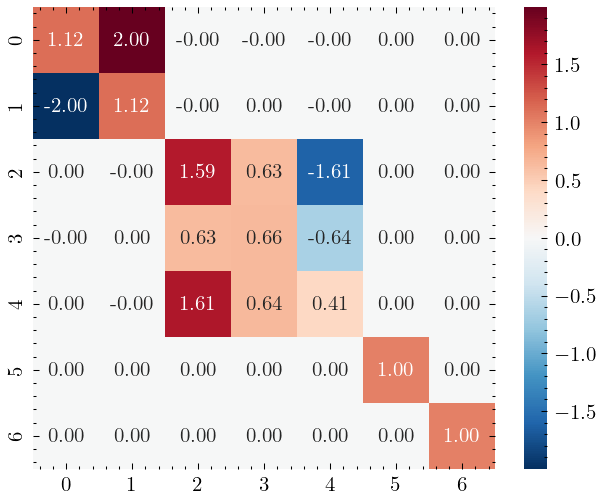

In [383]:
sns.heatmap(
    matrix[0],
    annot=True,
    cmap="RdBu_r",
    fmt=".2f",
    square=True,
)
print(force[0].round(decimals=5))

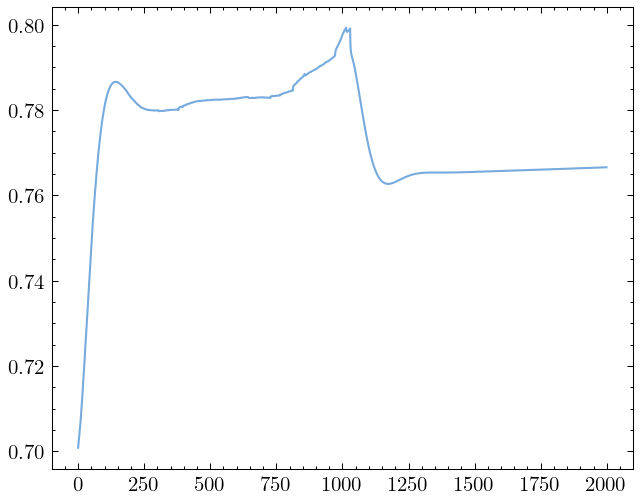

In [368]:
plt.plot(res[:,2])

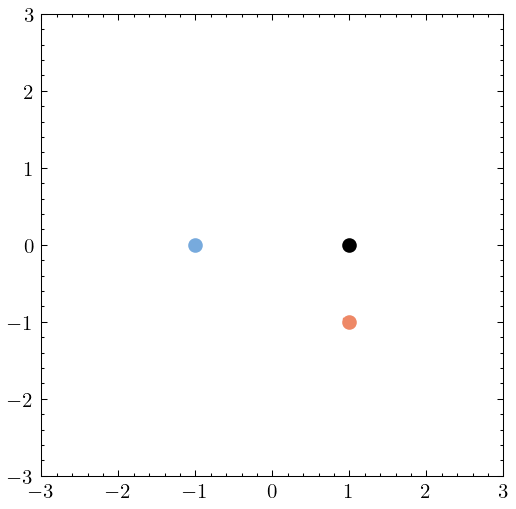

In [392]:
fig, ax = plt.subplots()
ax.scatter(res[0,0], res[0,1])
ax.plot(res[:,0], res[:, 1])
ax.scatter(res[0,5], res[0,6])
ax.plot(res[:,5], res[:,6])
ax.scatter(state[1].cpu(), state[2].cpu(), color='k')
ax.set_ylim([-3,3])
ax.set_xlim([-3,3])
ax.set_aspect('equal')

0
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
0


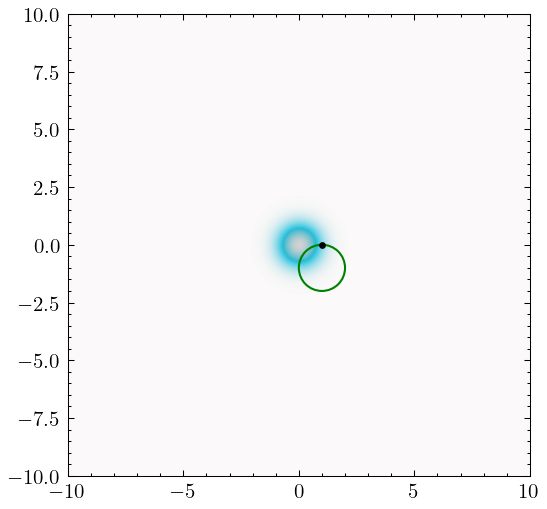

In [273]:
from matplotlib import animation
from matplotlib.patches import Circle
from cmap import Colormap, Color

_cmap = Colormap('colorcet:cet_cbtc2').to_mpl()
_cmap2 = Colormap('colorbrewer:YlGn_3').to_mpl()
cmap = Colormap([_cmap(0), _cmap(0), _cmap2(0.5), _cmap(0.5), _cmap2(1), _cmap(1)]).to_mpl()

frames = res[::10]

fig, ax = plt.subplots()
def update(i):
    print(i)
    ax.clear()
    m = skyrmion_m([mesh[0].cpu(), mesh[1].cpu()], frames[i]).numpy()
    B = vortex_field([mesh[0].cpu(), mesh[1].cpu()], state.cpu(), frames[i]).cpu().numpy()
    t = (((1 - m[:,:,2]) / 2))[...,None]
    image_skyrmion = np.clip(field_image(m, color='spirality'), 0,1)
    image_vortex = cmap(np.linalg.norm(B, axis=2))
    ax.imshow(image_skyrmion[::-1], extent=[-10, 10, -10, 10])
    ax.add_patch(Circle([frames[i, 5], frames[i, 6]], radius=1, color='green', fill=False))
    ax.scatter(state[1].cpu(), state[2].cpu(), color='k', marker='o', s=5)
ani = animation.FuncAnimation(fig, update, repeat=True, frames=len(frames), interval=50)
writer = animation.FFMpegWriter(fps=30)
ani.save(f"./thiele_tensor/vortex_attraction.mp4", writer=writer, dpi=200)

tensor(0.9995) tensor(-4.)


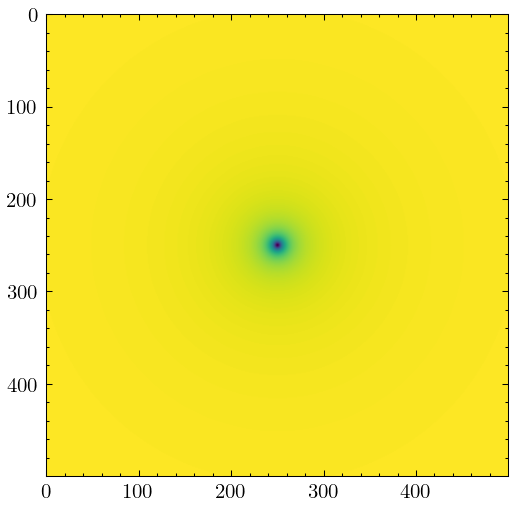

In [471]:
plt.imshow(vortex_field(mesh, state, res[0]).cpu()[...,2])

In [489]:
res[0, 2]

tensor(1.4888)

In [472]:
X, Y = mesh[:2]

In [508]:
X - res[0,6].detach()

tensor([[-7.0005, -6.9725, -6.9444,  ...,  6.9434,  6.9714,  6.9995],
        [-7.0005, -6.9725, -6.9444,  ...,  6.9434,  6.9714,  6.9995],
        [-7.0005, -6.9725, -6.9444,  ...,  6.9434,  6.9714,  6.9995],
        ...,
        [-7.0005, -6.9725, -6.9444,  ...,  6.9434,  6.9714,  6.9995],
        [-7.0005, -6.9725, -6.9444,  ...,  6.9434,  6.9714,  6.9995],
        [-7.0005, -6.9725, -6.9444,  ...,  6.9434,  6.9714,  6.9995]],
       device='mps:0')